In [7]:
import os
import chipwhisperer as cw

SCOPETYPE = 'CWNANO'
PLATFORM = 'CWNANO'

# Absolute path, so it doesn't depend on the kernel's working directory.
FW_DIR = r"C:\Users\Raphael\ChipWhisperer\chipwhisperer\firmware\mcu\stm32-gpio-tristate"
fw_path = os.path.join(FW_DIR, "gpio-tristate-{}.hex".format(PLATFORM))
assert os.path.isfile(fw_path), "Firmware not found: {} (cwd is {})".format(fw_path, os.getcwd())

# Release any scope left over from an earlier notebook run.
if "scope" in globals():
    scope.dis()

# Start fresh so the target uses the newly opened USB connection.
scope = cw.scope()
target = cw.target(scope)

cw.program_target(scope, cw.programmers.STM32FProgrammer, fw_path)

Detected known STMF32: STM32F04xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 2455 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 2455 bytes


Captured 5000 samples. Response: 


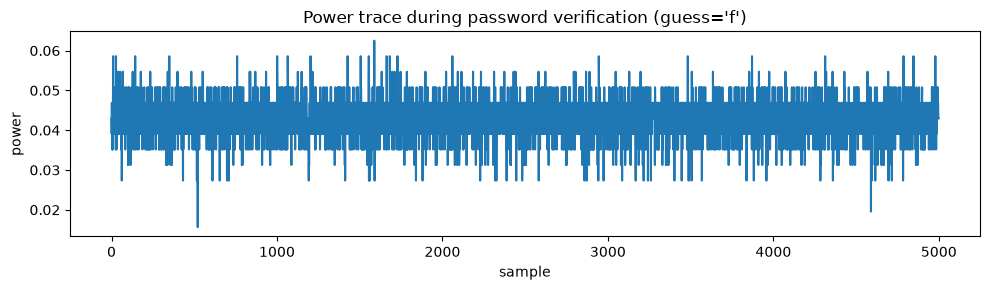

True

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import chipwhisperer as cw

# --- Connect to the Nano, talk to the EXTERNAL Arduino over UART ---
# Wiring (20-pin header on the Nano):
#   pin 2  -> Arduino GND
#   pin 8  -> Arduino 5V (VREF)
#   pin 10 -> Arduino RX   (Nano TX / tio ... serial_tx)
#   pin 12 -> Arduino TX   (Nano RX / tio ... serial_rx)
#   GPIO4 (trigger)  -> Arduino pin 13  (held HIGH during password verification)
#   Power probe: 100 ohm shunt on the ATmega VCC (pin 7), behind the RC pi filter.

if "scope" in globals():
    scope.dis()

scope = cw.scope()
scope.default_setup()          # 7.5 MHz ADC, 5000 samples, tio1=rx, tio2=tx
scope.adc.samples = 5000       # raise this if the active region is clipped (see plot)

target = cw.target(scope, cw.targets.SimpleSerial2)
target.baud = 9600

def capture_guess(guess, pad_len=16, fill="\x00"):
    """Send one password attempt and capture the power trace during verification.

    Arms BEFORE writing so we never miss pin-13's rising edge (the fixed GPIO4 trigger).
    Returns the trace (np.ndarray) or None if the trigger never fired (timeout).
    """
    # flush anything the target already sent
    try:
        target.ser.read(target.ser.in_waiting() or 0)
    except Exception:
        pass

    msg = guess.ljust(pad_len, fill)[:pad_len] + "\n"
    scope.arm()
    target.ser.write(msg.encode("latin-1"))
    timed_out = scope.capture()          # waits for GPIO4 rising edge (pin 13 high)
    if timed_out:
        return None
    return scope.get_last_trace()

# --- Sanity check: capture one trace and look at it ---
trace = capture_guess("f")
if trace is None:
    print("No trigger. Check that Arduino pin 13 is wired to the Nano GPIO4/trigger pin.")
else:
    print("Captured", len(trace), "samples. Response:", target.ser.read(50))
    plt.figure(figsize=(10, 3))
    plt.plot(trace)
    plt.title("Power trace during password verification (guess='f')")
    plt.xlabel("sample"); plt.ylabel("power"); plt.tight_layout(); plt.show()

scope.dis()